In [3]:
import os, sys
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

import pyspark
print(sys.version.split()[0], pyspark.__version__)

3.11.9 3.5.0


In [4]:
DATA_DIR = "network_operator_KPIs_time_series_dataset/data_series"
INTERNET_SERIES = [f"s{i}" for i in range(1, 11)]
START_DATE = "2023-01-01 00:00:00"
PEAK_HOURS = (18, 23)
OUT_DIR = "output"

In [5]:
from pyspark.sql import SparkSession, functions as F
spark = SparkSession.builder.appName("InternetUsage").getOrCreate()
spark.sparkContext.setLogLevel("ERROR")
print("Spark version:", spark.version)

Spark version: 3.5.0


In [6]:
frames = []
for sid in INTERNET_SERIES:
    d = (spark.read.option("sep", " ").option("inferSchema", True)
         .csv(f"{DATA_DIR}/{sid}.txt").toDF("t_sec", "traffic")
         .withColumn("site", F.lit(sid)))
    frames.append(d)
raw = frames[0]
for f in frames[1:]:
    raw = raw.unionByName(f)
print("Rows:", raw.count())
raw.show(5)
raw.printSchema()

Rows: 107380
+-----+------------------+----+
|t_sec|           traffic|site|
+-----+------------------+----+
|    0|309.63413722707816|  s1|
|  300|300.17454480088946|  s1|
|  600|289.49900721247286|  s1|
|  900|280.83066222579055|  s1|
| 1200| 273.6886439905293|  s1|
+-----+------------------+----+
only showing top 5 rows

root
 |-- t_sec: integer (nullable = true)
 |-- traffic: double (nullable = true)
 |-- site: string (nullable = false)



In [7]:
raw = (raw.dropna()
          .withColumn("ts", (F.unix_timestamp(F.lit(START_DATE)) + F.col("t_sec")).cast("timestamp")))
raw.show(5)

+-----+------------------+----+-------------------+
|t_sec|           traffic|site|                 ts|
+-----+------------------+----+-------------------+
|    0|309.63413722707816|  s1|2023-01-01 00:00:00|
|  300|300.17454480088946|  s1|2023-01-01 00:05:00|
|  600|289.49900721247286|  s1|2023-01-01 00:10:00|
|  900|280.83066222579055|  s1|2023-01-01 00:15:00|
| 1200| 273.6886439905293|  s1|2023-01-01 00:20:00|
+-----+------------------+----+-------------------+
only showing top 5 rows



In [8]:
feat = (raw.withColumn("date", F.to_date("ts"))
           .withColumn("hour", F.hour("ts"))
           .withColumn("dow", F.dayofweek("ts") - 1)
           .withColumn("is_peak", F.when(F.col("hour").between(*PEAK_HOURS), 1).otherwise(0)))
feat.select("ts", "traffic", "hour", "dow", "is_peak").show(5)

+-------------------+------------------+----+---+-------+
|                 ts|           traffic|hour|dow|is_peak|
+-------------------+------------------+----+---+-------+
|2023-01-01 00:00:00|309.63413722707816|   0|  0|      0|
|2023-01-01 00:05:00|300.17454480088946|   0|  0|      0|
|2023-01-01 00:10:00|289.49900721247286|   0|  0|      0|
|2023-01-01 00:15:00|280.83066222579055|   0|  0|      0|
|2023-01-01 00:20:00| 273.6886439905293|   0|  0|      0|
+-------------------+------------------+----+---+-------+
only showing top 5 rows



In [9]:
hourly = (feat.groupBy("site", "date", "hour", "dow", "is_peak")
              .agg(F.sum("traffic").alias("usage"))
              .withColumn("day_idx", F.datediff("date", F.lit(START_DATE.split()[0]).cast("date"))))
print("Hourly rows:", hourly.count())
hourly.orderBy("site", "date", "hour").show(5)

Hourly rows: 8950
+----+----------+----+---+-------+------------------+-------+
|site|      date|hour|dow|is_peak|             usage|day_idx|
+----+----------+----+---+-------+------------------+-------+
|  s1|2023-01-01|   0|  0|      0| 3128.125888751178|      0|
|  s1|2023-01-01|   1|  0|      0| 2078.628467101514|      0|
|  s1|2023-01-01|   2|  0|      0|1457.3177036692196|      0|
|  s1|2023-01-01|   3|  0|      0|1088.7660112765204|      0|
|  s1|2023-01-01|   4|  0|      0|1005.1197603974152|      0|
+----+----------+----+---+-------+------------------+-------+
only showing top 5 rows



In [10]:
max_day = hourly.agg(F.max("day_idx")).first()[0]
cut = int(max_day * 0.8)
train = hourly.filter(F.col("day_idx") <= cut)
test = hourly.filter(F.col("day_idx") > cut)
print("Train rows:", train.count(), "| Test rows:", test.count())

Train rows: 7200 | Test rows: 1750


In [11]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import OneHotEncoder, VectorAssembler
from pyspark.ml.regression import LinearRegression

enc = OneHotEncoder(inputCols=["hour", "dow"], outputCols=["hour_oh", "dow_oh"])
asm = VectorAssembler(inputCols=["hour_oh", "dow_oh", "is_peak", "day_idx"], outputCol="features")
lr = LinearRegression(featuresCol="features", labelCol="usage", predictionCol="prediction")
model = Pipeline(stages=[enc, asm, lr]).fit(train)
pred = model.transform(test)
pred.select("site", "date", "hour", "usage", "prediction").show(5)

+----+----------+----+------------------+------------------+
|site|      date|hour|             usage|        prediction|
+----+----------+----+------------------+------------------+
|  s1|2023-02-04|   2|1468.1499014520534|1217.8839047882138|
|  s1|2023-02-05|  16| 5766.586494620438|5838.0811253419815|
|  s1|2023-02-06|  18|5698.5661047832045|  5963.27363168354|
|  s1|2023-02-02|  17| 5035.972667278587| 5822.381671144431|
|  s1|2023-02-04|   4| 903.6058984421763| 744.5252307414958|
+----+----------+----+------------------+------------------+
only showing top 5 rows



In [12]:
from pyspark.ml.evaluation import RegressionEvaluator
mae = RegressionEvaluator(labelCol="usage", predictionCol="prediction", metricName="mae").evaluate(pred)
avg_usage = test.agg(F.avg("usage")).first()[0]
print(f"Test MAE: {mae:.2f}")
print(f"Average usage in test set: {avg_usage:.2f}")

Test MAE: 558.55
Average usage in test set: 4363.07


In [13]:
from pyspark.ml.feature import StringIndexer

idx = StringIndexer(inputCol="site", outputCol="site_idx")
enc2 = OneHotEncoder(inputCols=["hour", "dow", "site_idx"], outputCols=["hour_oh", "dow_oh", "site_oh"])
asm2 = VectorAssembler(inputCols=["hour_oh", "dow_oh", "site_oh", "is_peak", "day_idx"], outputCol="features")
model2 = Pipeline(stages=[idx, enc2, asm2, lr]).fit(train)
pred2 = model2.transform(test)

mae2 = RegressionEvaluator(labelCol="usage", predictionCol="prediction", metricName="mae").evaluate(pred2)
print(f"MAE without site: {mae:.2f} ({100*mae/avg_usage:.1f}%)")
print(f"MAE with site:    {mae2:.2f} ({100*mae2/avg_usage:.1f}%)")

MAE without site: 558.55 (12.8%)
MAE with site:    459.89 (10.5%)


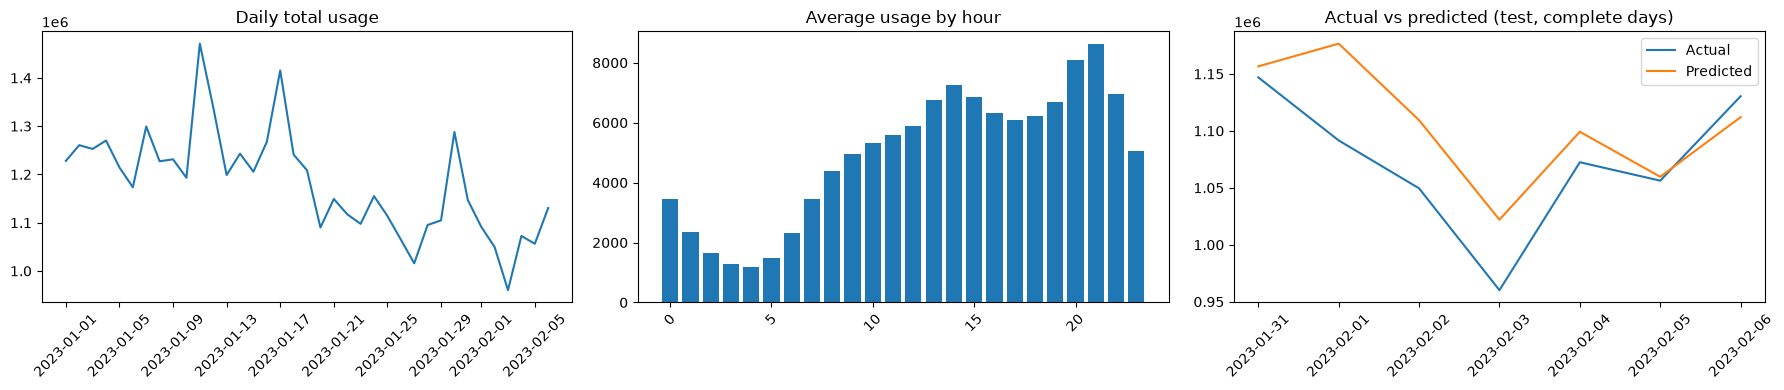

In [14]:
import matplotlib.pyplot as plt
pred = pred2
mae = mae2

complete = hourly.groupBy("date").count().filter(F.col("count") == 240).select("date")

daily_pd = (hourly.join(complete, "date")
                  .groupBy("date").agg(F.sum("usage").alias("total_usage"))
                  .orderBy("date").toPandas())
hour_pd = hourly.groupBy("hour").agg(F.avg("usage").alias("avg_usage")).orderBy("hour").toPandas()
avp_pd = (pred.join(complete, "date")
              .groupBy("date").agg(F.sum("usage").alias("actual"), F.sum("prediction").alias("predicted"))
              .orderBy("date").toPandas())

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
ax[0].plot(daily_pd["date"], daily_pd["total_usage"]); ax[0].set_title("Daily total usage")
ax[1].bar(hour_pd["hour"], hour_pd["avg_usage"]); ax[1].set_title("Average usage by hour")
ax[2].plot(avp_pd["date"], avp_pd["actual"], label="Actual")
ax[2].plot(avp_pd["date"], avp_pd["predicted"], label="Predicted"); ax[2].legend(); ax[2].set_title("Actual vs predicted (test, complete days)")
for a in ax: a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

In [15]:
import os, pandas as pd
os.makedirs(OUT_DIR, exist_ok=True)
daily_pd.to_csv(f"{OUT_DIR}/daily_trend.csv", index=False)
hour_pd.to_csv(f"{OUT_DIR}/hourly_pattern.csv", index=False)
avp_pd.to_csv(f"{OUT_DIR}/actual_vs_predicted.csv", index=False)
(hourly.groupBy("is_peak").agg(F.sum("usage").alias("total_usage"))
       .withColumn("period", F.when(F.col("is_peak") == 1, "Peak").otherwise("Off-peak"))
       .toPandas().to_csv(f"{OUT_DIR}/peak_vs_offpeak.csv", index=False))
pd.DataFrame({"total_traffic": [hourly.agg(F.sum("usage")).first()[0]], "mae": [mae]}).to_csv(f"{OUT_DIR}/kpis.csv", index=False)
print("MAE exported:", round(mae, 2))
print(os.listdir(OUT_DIR))

MAE exported: 459.89
['.ipynb_checkpoints', 'actual_vs_predicted.csv', 'daily_trend.csv', 'hourly_pattern.csv', 'kpis.csv', 'peak_vs_offpeak.csv']
